In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn openpyxl jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 111.1 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/KaggleV2-May-2016.csv")
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["No-show"].value_counts())

Shape: (107920, 14)
      PatientId  AppointmentID Gender          ScheduledDay  \
0  2.987250e+13        5642903      F  2016-04-29T18:38:08Z   
1  5.589978e+14        5642503      M  2016-04-29T16:08:27Z   
2  4.262962e+12        5642549      F  2016-04-29T16:19:04Z   
3  8.679512e+11        5642828      F  2016-04-29T17:29:31Z   
4  8.841186e+12        5642494      F  2016-04-29T16:07:23Z   

         AppointmentDay   Age      Neighbourhood  Scholarship  Hipertension  \
0  2016-04-29T00:00:00Z  62.0    JARDIM DA PENHA          0.0           1.0   
1  2016-04-29T00:00:00Z  56.0    JARDIM DA PENHA          0.0           0.0   
2  2016-04-29T00:00:00Z  62.0      MATA DA PRAIA          0.0           0.0   
3  2016-04-29T00:00:00Z   8.0  PONTAL DE CAMBURI          0.0           0.0   
4  2016-04-29T00:00:00Z  56.0    JARDIM DA PENHA          0.0           1.0   

   Diabetes  Alcoholism  Handcap  SMS_received No-show  
0       0.0         0.0      0.0           0.0      No  
1       0.0 

In [3]:
df["ScheduledDay"] = pd.to_datetime(
    df["ScheduledDay"], utc=True, errors="coerce"
)
df["AppointmentDay"] = pd.to_datetime(
    df["AppointmentDay"], utc=True, errors="coerce"
)

df["WaitingDays"] = (
    df["AppointmentDay"].dt.normalize()
    - df["ScheduledDay"].dt.normalize()
).dt.days

df["AppointmentDayOfWeek"] = (
    df["AppointmentDay"].dt.day_name()
)

df["NoShow"] = (
    df["No-show"].str.strip().str.lower().eq("yes").astype(int)
)

print("Negative ages:", (df["Age"] < 0).sum())
print("Negative waiting days:", (df["WaitingDays"] < 0).sum())

df = df[
    (df["Age"] >= 0) &
    (df["WaitingDays"] >= 0)
].copy()

print("Cleaned shape:", df.shape)

Negative ages: 1
Negative waiting days: 5
Cleaned shape: (107913, 17)


In [4]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[-1, 17, 34, 49, 64, 120],
    labels=["0-17", "18-34", "35-49", "50-64", "65+"]
)

df["WaitingGroup"] = pd.cut(
    df["WaitingDays"],
    bins=[-1, 0, 3, 7, 14, 30, 180],
    labels=[
        "Same day", "1-3 days", "4-7 days",
        "8-14 days", "15-30 days", "31+ days"
    ]
)

print(df[["Age", "AgeGroup", "WaitingDays", "WaitingGroup"]].head())

    Age AgeGroup  WaitingDays WaitingGroup
0  62.0    50-64          0.0     Same day
1  56.0    50-64          0.0     Same day
2  62.0    50-64          0.0     Same day
3   8.0     0-17          0.0     Same day
4  56.0    50-64          0.0     Same day


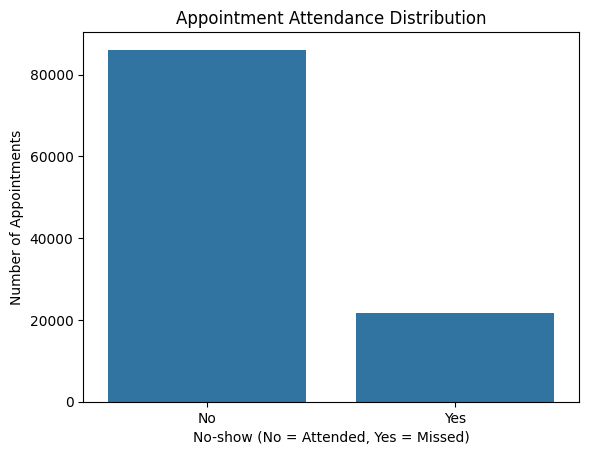

In [5]:
sns.countplot(data=df, x="No-show")
plt.title("Appointment Attendance Distribution")
plt.xlabel("No-show (No = Attended, Yes = Missed)")
plt.ylabel("Number of Appointments")
plt.show()

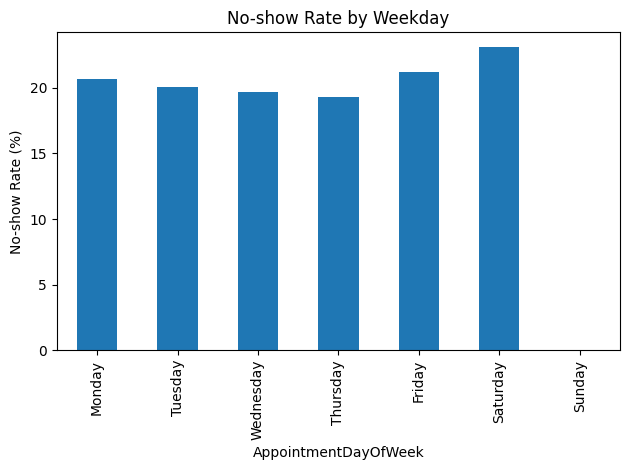

In [6]:
weekday_rate = df.groupby(
    "AppointmentDayOfWeek"
)["NoShow"].mean().reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]) * 100

weekday_rate.plot(kind="bar")
plt.title("No-show Rate by Weekday")
plt.ylabel("No-show Rate (%)")
plt.tight_layout()
plt.show()

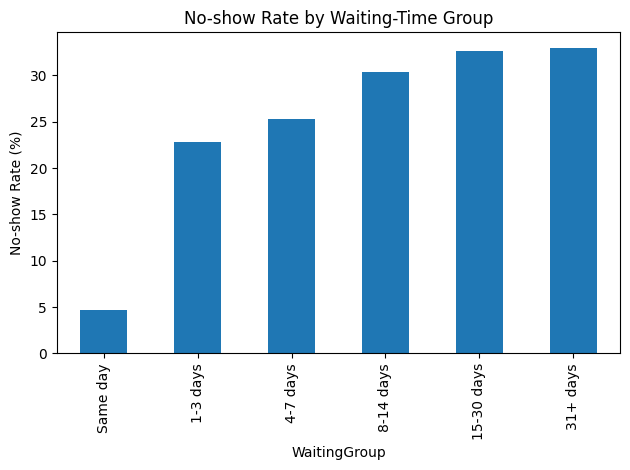

In [7]:
waiting_rate = df.groupby(
    "WaitingGroup", observed=False
)["NoShow"].mean() * 100

waiting_rate.plot(kind="bar")
plt.title("No-show Rate by Waiting-Time Group")
plt.ylabel("No-show Rate (%)")
plt.tight_layout()
plt.show()

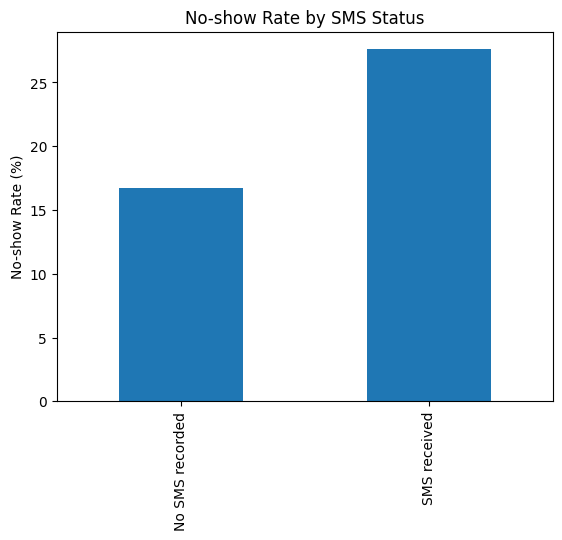

In [8]:
sms_rate = df.groupby("SMS_received")["NoShow"].mean() * 100

sms_rate.index = ["No SMS recorded", "SMS received"]
sms_rate.plot(kind="bar")
plt.title("No-show Rate by SMS Status")
plt.ylabel("No-show Rate (%)")
plt.show()

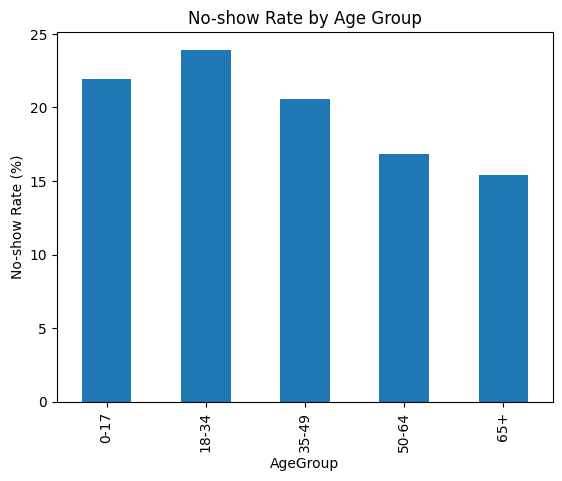

In [9]:
age_rate = df.groupby(
    "AgeGroup", observed=False
)["NoShow"].mean() * 100

age_rate.plot(kind="bar")
plt.title("No-show Rate by Age Group")
plt.ylabel("No-show Rate (%)")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

features = [
    "Age", "Gender", "WaitingDays",
    "AppointmentDay", "SMS_received",
    "Scholarship", "Hipertension",
    "Diabetes", "Alcoholism", "Handcap",
    "Neighbourhood"
]

# Use the weekday derived from AppointmentDay, not the raw date.
df["AppointmentDayOfWeekNum"] = pd.to_datetime(
    df["AppointmentDay"], utc=True
).dt.dayofweek

features[features.index("AppointmentDay")] = "AppointmentDayOfWeekNum"

X = pd.get_dummies(df[features], drop_first=True)
y = df["NoShow"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, zero_division=0))
print("Recall:", recall_score(y_test, pred, zero_division=0))
print("F1-score:", f1_score(y_test, pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, prob))
print(confusion_matrix(y_test, pred))

Accuracy: 0.5811054996988371
Precision: 0.30279790999494355
Recall: 0.8238936023847742
F1-score: 0.4428421766192149
ROC-AUC: 0.7328617792906909
[[8949 8273]
 [ 768 3593]]


In [12]:
import pandas as pd
from IPython.display import display, FileLink

# Save the cleaned DataFrame as an Excel file
output_file = "cleaned_appointments.xlsx"

# Create a copy for export and make datetime columns timezone-unaware
df_export = df.copy()
for col in ["ScheduledDay", "AppointmentDay"]:
    if col in df_export.columns and pd.api.types.is_datetime64_any_dtype(df_export[col]):
        df_export[col] = df_export[col].dt.tz_localize(None)

df_export.to_excel(output_file, index=False, engine="openpyxl")

print("Cleaned dataset saved successfully!")
print("Total records:", len(df_export))
print("Total columns:", len(df_export.columns))

# Display a download link in Jupyter Notebook
display(FileLink(output_file))

Cleaned dataset saved successfully!
Total records: 107913
Total columns: 20


/content/cleaned_appointments.xlsx